<h2>
  Vignette 05: Spatial -> Single Cell Pipeline<br>
  <span style="font-size: 12px; font-weight: normal; display: block">
    <i>"I'm not like them but I can pretend" -- Nirvana</i><br>
  </span>
</h2>

Platpy is designed to be a lightweight framework that plays well with the scanpy/squidpy (et al.) universe; these tools are widely used and well tested, and there's no need to re-invent them.  Here we show the interoperability of platpy with Scanpy.  We will use platpy to create a scanpy compatible anndata object that can feed directly into spatial analysis.t.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import matplotlib.pyplot as plt
import tqdm as notebook_tqdm

from platpy.io_utils import load_sample
from platpy.plot_utils import plot_image_grid, PlotObject
from platpy.cell_utils import build_cells_xenium
from platpy.spatial_tools import load_rois, annotate_roi_membership

# --- UPDATE THIS PATH ---
save_dir = Path.home() / "platpy_data" / "XeniumSamples"

master = load_sample(str(save_dir / "WT_02"))

print(f"Images: {list(master.images.keys())}")
print(f"Omics:  {list(master.omics.keys())}")
tx_obs = master.omics['transcripts'].data.obs
print(f"Transcript table: {tx_obs.shape[0]:,} rows  |  columns: {list(tx_obs.columns)}")

C:\Users\maynard\AppData\Local\miniconda3\envs\platpy\Lib\site-packages\docrep\decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
C:\Users\maynard\AppData\Local\miniconda3\envs\platpy\Lib\site-packages\docrep\decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


  - Images available: 'DAPI' (8g), 'Marker_1' (8g), 'Marker_2' (8g), 'Marker_3' (8g)


  - Image channels loaded: DAPI, Marker_1, Marker_2, Marker_3
  - Omic channels loaded: transcripts
  - Cell channels loaded: cell_boundaries
  - ROIs loaded: 
Images: ['DAPI', 'Marker_1', 'Marker_2', 'Marker_3']
Omics:  ['transcripts']
Transcript table: 11,084,660 rows  |  columns: ['transcript_id', 'cell_id', 'feature', 'x', 'y', 'qv']


### Step 1: Build a cell × gene expression matrix

Xenium stores every detected transcript individually.  To use this data with scanpy/squidpy etc., 
we need to convert this into a standard **cells × genes** count matrix — one row per cell, 
one column per gene, values = transcript counts. Cell centroids are computed as the mean (x, y) 
position of each cell's transcripts, giving us absolute micron coordinates that carry through the 
entire analysis.

In [2]:
adata = build_cells_xenium(master)
print(adata)
print()
print(adata.obs.head())

Dropped 16,377 codeword transcripts (NegControl/Unassigned/Deprecated/BLANK)
Transcripts assigned to cells: 9,922,856


  Cells: 40,826   Genes: 374


AnnData object with n_obs × n_vars = 40826 × 374
    obs: 'sample_id', 'x_micron', 'y_micron', 'n_transcripts', 'n_genes'
    uns: 'spatial'
    obsm: 'spatial'

           sample_id     x_micron     y_micron  n_transcripts  n_genes
cell_id                                                               
afcagegh-1     WT_02  8216.595703  2488.808838            194       96
afcahkfi-1     WT_02  8202.904297  2512.391846            338      120
afcajilh-1     WT_02  8212.211914  2505.394531            148       71
afcajlef-1     WT_02  8218.323242  2499.864990            150       88
afcakchk-1     WT_02  8225.619141  2495.366455            229      115


### Step 2: Define spatial ROIs

By using the ViewPort to convert a view to a pixel image and back to micron coordinates, it's straightforward to make polygon ROIs to map out cortex, striatum and septum on a specimen.  For demonstration purposes, we'll use a pre-drawn ROI that is saved as a JSON file in the ./demo/ directory.  If you want to draw your own ROIs, the interactive code is in `draw_rois.py`, which is also in the ./demo/ directory.

ROIs loaded: ['cortex', 'septum', 'striatum']
region
cortex        22504
striatum       8707
unassigned     7397
septum         2218
Name: count, dtype: int64


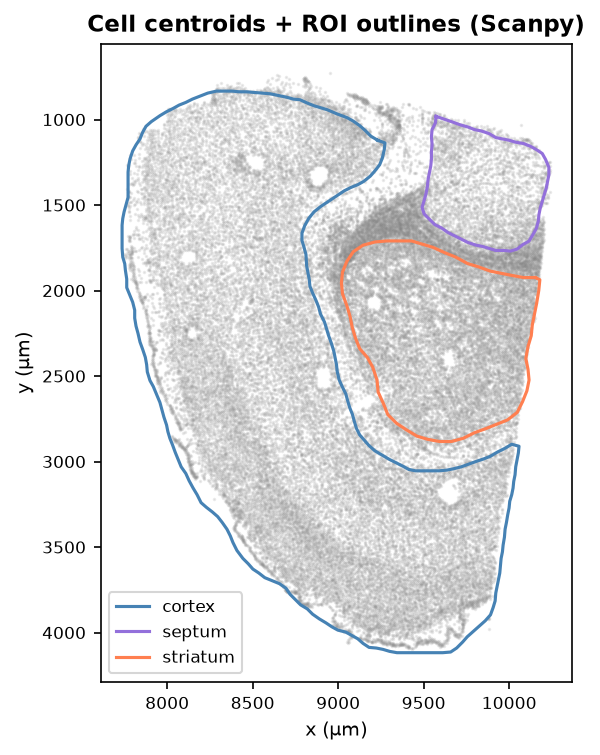

In [3]:
rois = load_rois(Path("demo/WT_02_region_rois.json"))
print(f"ROIs loaded: {list(rois.keys())}")

roi_colors = {'cortex': 'steelblue', 'striatum': 'coral', 'septum': 'mediumpurple'}

plot_image_grid(
    PlotObject(adata, plot_type='scatter', base_color='gray',
               rois=rois, roi_colors=roi_colors,
               title='Cell centroids + ROI outlines (Scanpy)', s=0.5, alpha=0.15),
               width=4
)

# Now let's annotate the cells with their ROI membership.  The annotate_roi_membership function 
# adds a new column to adata.obs for the ROI name.  In the case of overlapping ROIs, it has several
# options for how to handle assignment.  In addition, some downstream analyses may prefer unassigned
# cells to not have any entry at all ('NaN'), but in this case we'll tell it to label them 'unassigned'

adata = annotate_roi_membership(adata, rois, col='region',
                                cell_duplicates='first_match',
                                unassigned_label='unassigned')
print(adata.obs['region'].value_counts())

### Step 3: Scanpy — PCA → UMAP

Now that we have our data imported into Scanpy, we'll use it in a standard scRNA-seq pipeline -- we'll UMAP cluster the cells.   We can use our spatial annotations within Scanpy to identify which clusters are specific to each brain compartment.

In [4]:
########
## This is a standard Scanpy workflow for basic QC and dimensionality reduction / UMAP embedding.
########

# Basic QC filtering
sc.pp.filter_cells(adata, min_genes=5)    # drop cells with fewer than 5 detected genes
sc.pp.filter_genes(adata, min_cells=10)   # drop genes seen in fewer than 10 cells
print(f"After filtering: {adata.shape[0]:,} cells x {adata.shape[1]:,} genes")

# Normalize to a common library size, then log-transform
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Select the most variable genes to focus the embedding
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
print(f"Highly variable genes: {adata.var['highly_variable'].sum()}")

# PCA -> neighbor graph -> UMAP -> Leiden clusters
sc.pp.pca(adata, mask_var="highly_variable")
sc.pp.neighbors(adata, n_neighbors=15)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.5, flavor='igraph', n_iterations=2, directed=False)
print(f"Leiden clusters: {adata.obs['leiden'].nunique()}  (resolution=0.5)")

After filtering: 40,711 cells x 374 genes


Highly variable genes: 374


Leiden clusters: 11  (resolution=0.5)


### Step 4: Scanpy's spatial output: Three views, one story

Left: expression clusters in UMAP space. Center: the same cells in absolute micron coordinates, colored by anatomical ROI. Right: UMAP colored by spatial origin. If the biology is working, expression space and physical space should carve the tissue the same way.

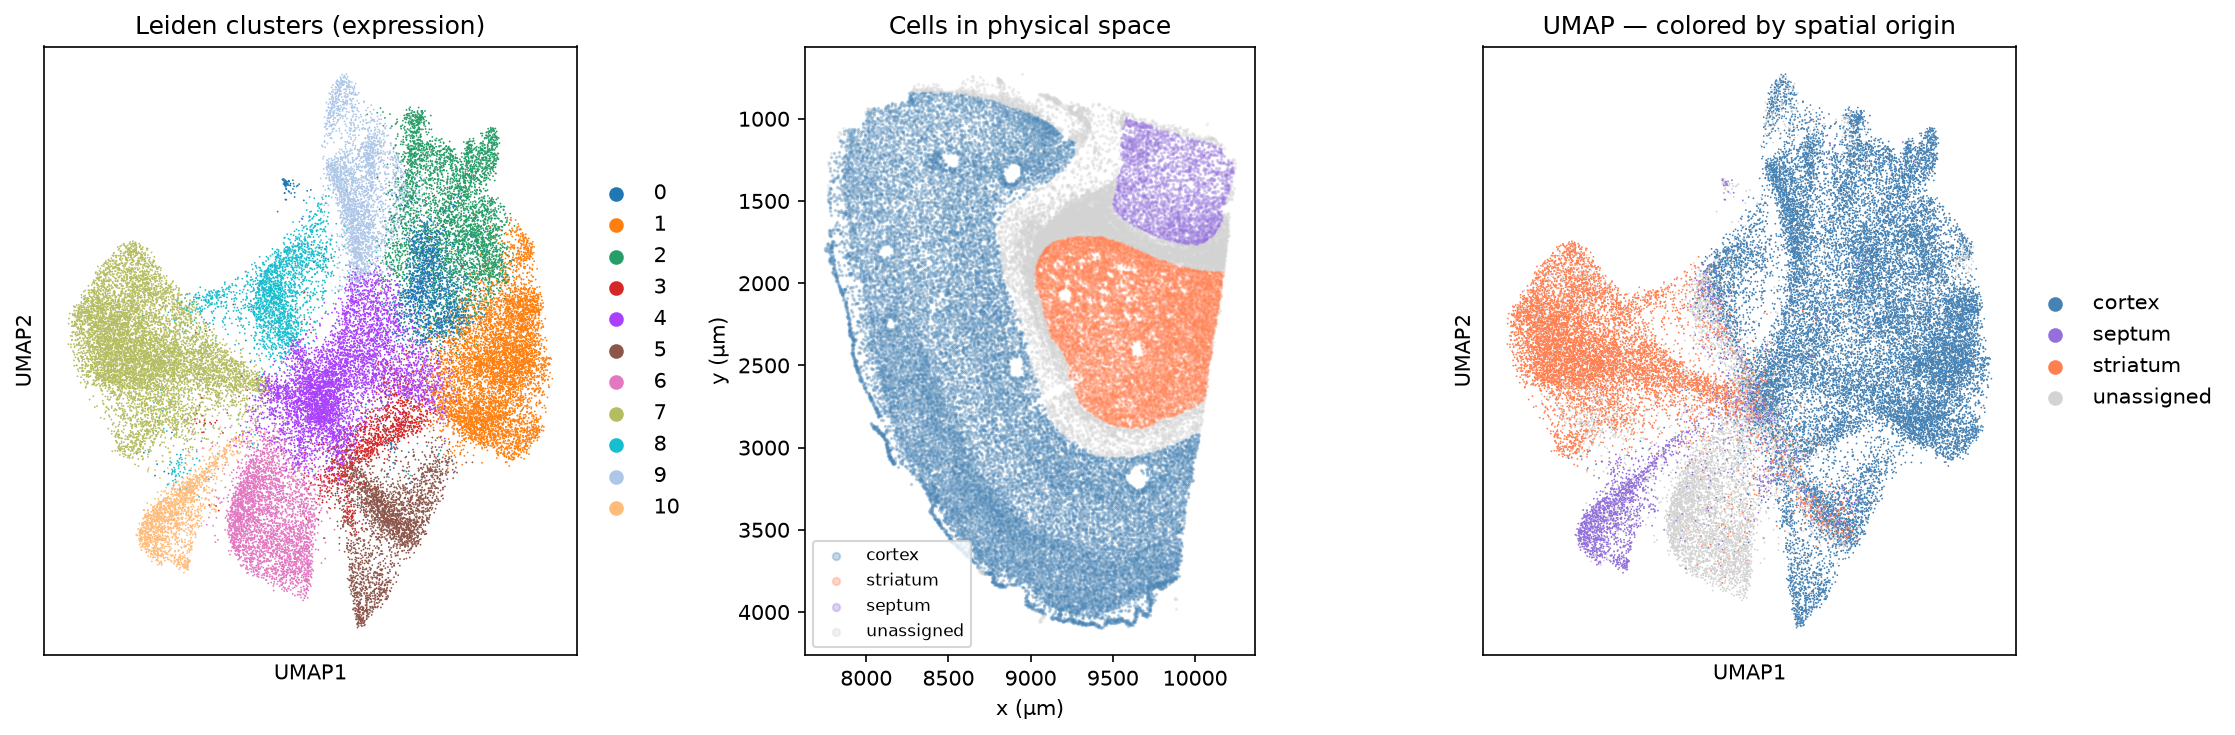

In [5]:
########
## This is a standard Scanpy workflow for visualization.
########

region_colors = {'cortex': 'steelblue', 'striatum': 'coral',
                 'septum': 'mediumpurple', 'unassigned': 'lightgray'}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=150)

# Panel 1: Leiden clusters in UMAP space (Scanpy)
sc.pl.umap(adata, color='leiden', ax=axes[0], show=False,
           title='Leiden clusters (expression)')

# Panel 2: cells in physical space colored by anatomical ROI (Scanpy)
for region, color in region_colors.items():
    mask = adata.obs['region'] == region
    axes[1].scatter(adata.obs.loc[mask, 'x_micron'], adata.obs.loc[mask, 'y_micron'],
                    c=color, s=0.5, alpha=0.3, label=region, rasterized=True)
axes[1].set_aspect('equal')
axes[1].invert_yaxis()
axes[1].legend(markerscale=5, loc='lower left', fontsize=8)
axes[1].set(title='Cells in physical space', xlabel='x (µm)', ylabel='y (µm)')

# Panel 3: UMAP colored by spatial origin (Scanpy)
sc.pl.umap(adata, color='region', ax=axes[2], show=False, palette=region_colors,
           title='UMAP — colored by spatial origin')

plt.tight_layout()
plt.show()

### Step 5: Integration with Squidpy — spatial neighborhood enrichment

Platpy doesn't try to replace squidpy — it just makes the handoff clean.  Because our
cell coordinates are in **absolute micron space**, we can pass squidpy a biologically
meaningful neighbor radius (50 µm ≈ 2-3 cell diameters) rather than an arbitrary pixel
count that depends on imaging resolution.

The neighborhood enrichment asks: *do cells of region A border cells of region B more or
less than you'd expect by chance?*  The z-score heatmap answers that directly — positive
means enriched contact, negative means depleted.

We're going to take the `adata` that we extracted and annotated and let Squidpy work with it.  
This following is a standard Squidpy workflow, all platpy does is hand it properly annotated 
data.  We'll plot it next to the UMAP and spatial context for each ROI for context.

INFO     Creating graph using `None` transform and `1` libraries.                                                  


C:\Users\maynard\AppData\Local\Temp\ipykernel_51332\3028738201.py:45: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata_roi, spatial_key='spatial', coord_type='generic', radius=50)


  0%|          | 0/1000 [00:00<?, ?/s]

INFO     Creating graph using `None` transform and `1` libraries.                                                  


C:\Users\maynard\AppData\Local\Temp\ipykernel_51332\3028738201.py:45: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata_roi, spatial_key='spatial', coord_type='generic', radius=50)


  0%|          | 0/1000 [00:00<?, ?/s]

INFO     Creating graph using `None` transform and `1` libraries.                                                  


C:\Users\maynard\AppData\Local\Temp\ipykernel_51332\3028738201.py:45: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata_roi, spatial_key='spatial', coord_type='generic', radius=50)


  0%|          | 0/1000 [00:00<?, ?/s]

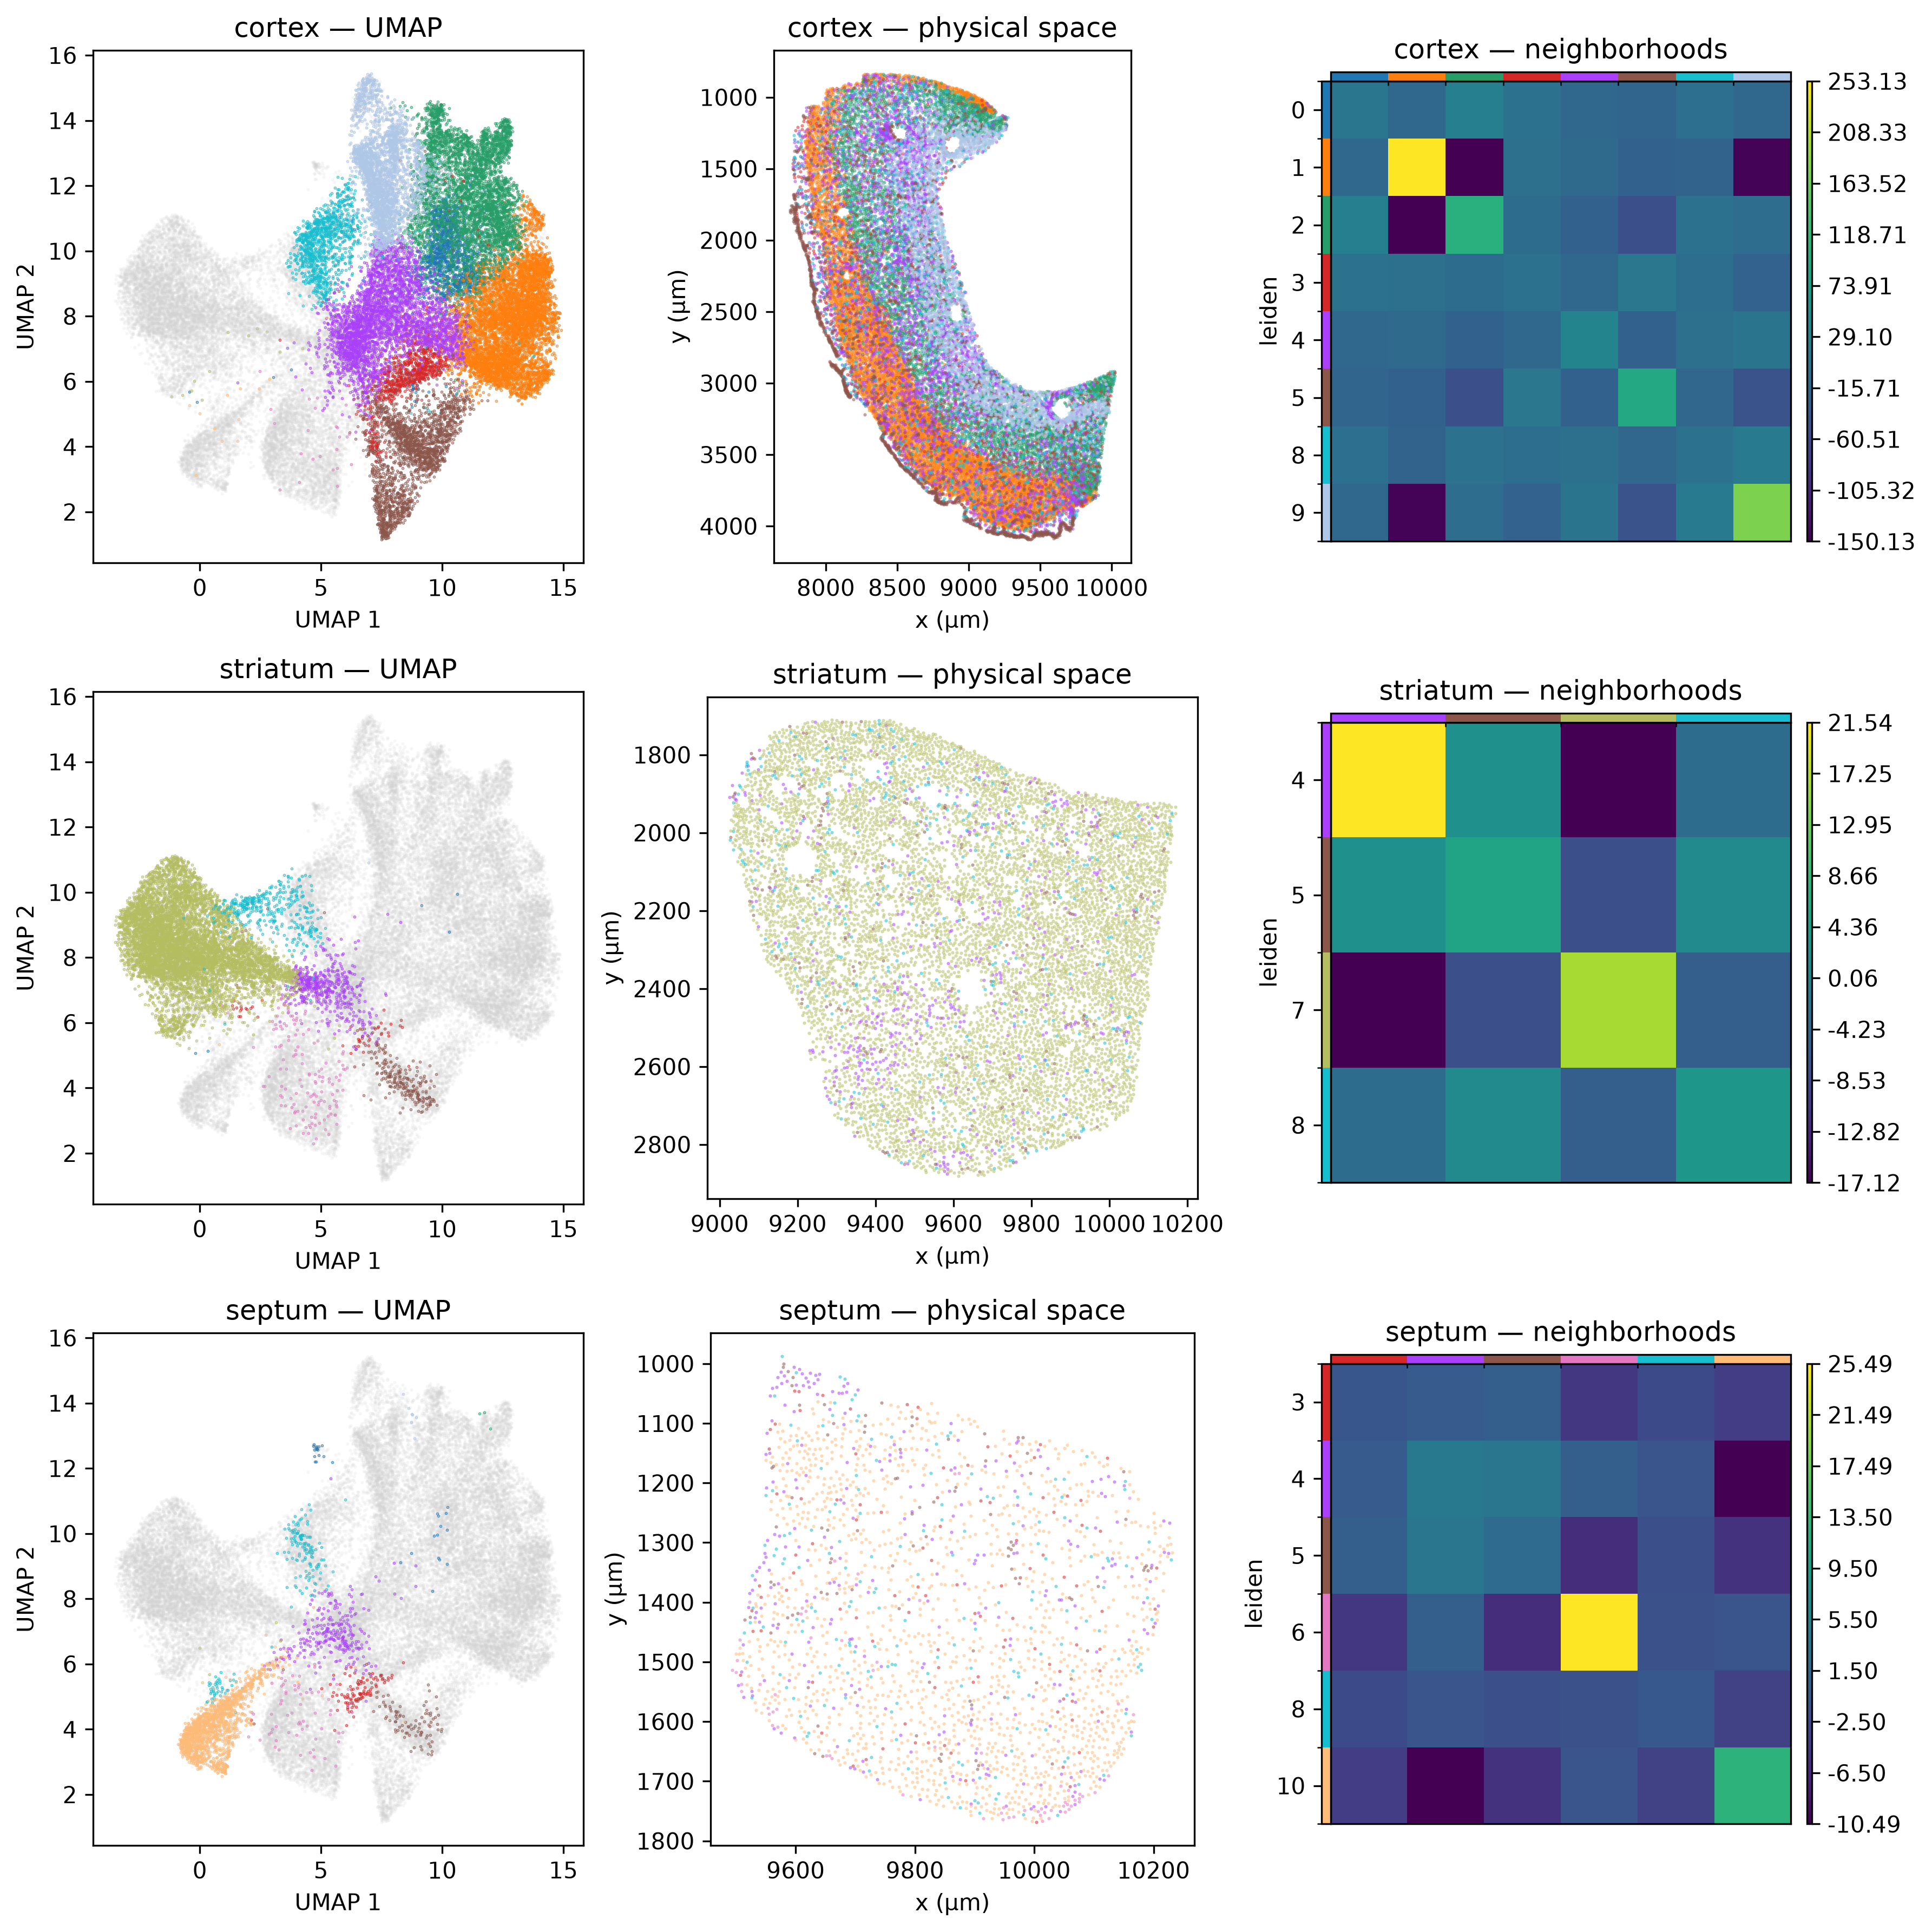

In [6]:
########
## This is a standard Scanpy/Squidpy workflow for visualization.
########

umap_coords    = adata.obsm['X_umap']
categories     = adata.obs['leiden'].cat.categories.tolist()
cluster_colors = dict(zip(categories, adata.uns['leiden_colors']))

# Clusters representing less than this % of a ROI's cells are excluded.
# Prevents rare contaminant cells from expanding the neighborhood matrix.
min_cluster_pct = 2.5

fig, axes = plt.subplots(3, 3, figsize=(12, 12), dpi=300)

for row, roi_name in enumerate(['cortex', 'striatum', 'septum']):
    roi_mask  = (adata.obs['region'] == roi_name).values
    adata_roi = adata[roi_mask].copy()

    # Drop clusters below the minimum threshold for this ROI
    pct       = adata_roi.obs['leiden'].value_counts() / len(adata_roi) * 100
    adata_roi = adata_roi[adata_roi.obs['leiden'].isin(pct[pct >= min_cluster_pct].index)].copy()

    # Col 0: full UMAP — gray background, ROI cells highlighted by cluster (Scanpy)
    ax = axes[row, 0]
    ax.scatter(umap_coords[:, 0], umap_coords[:, 1],
               c='lightgray', s=0.2, alpha=0.2)
    for cat in categories:
        m = roi_mask & (adata.obs['leiden'] == cat).values
        if m.sum():
            ax.scatter(umap_coords[m, 0], umap_coords[m, 1],
                       c=cluster_colors[cat], s=0.1, alpha=0.8)
    ax.set(title=f'{roi_name} — UMAP', xlabel='UMAP 1', ylabel='UMAP 2')

    # Col 1: physical space — ROI cells only, colored by cluster (Scanpy)
    ax = axes[row, 1]
    for cat in adata_roi.obs['leiden'].cat.categories:
        m = adata_roi.obs['leiden'] == cat
        ax.scatter(adata_roi.obs.loc[m, 'x_micron'], adata_roi.obs.loc[m, 'y_micron'],
                   c=cluster_colors[cat], s=0.2, alpha=0.6)
    ax.set_aspect('equal')
    ax.invert_yaxis()
    ax.set(title=f'{roi_name} — physical space', xlabel='x (µm)', ylabel='y (µm)')

    # Col 2: neighborhood enrichment within this ROI (Squidpy)
    sq.gr.spatial_neighbors(adata_roi, spatial_key='spatial', coord_type='generic', radius=50)
    sq.gr.nhood_enrichment(adata_roi, cluster_key='leiden')
    sq.pl.nhood_enrichment(adata_roi, cluster_key='leiden', mode='zscore',
                           ax=axes[row, 2], title=f'{roi_name} — neighborhoods')

plt.tight_layout()
plt.show()

#### Single-cell analysis stays connected to physical space
In this example, you may have noticed a few key things:

- **The transcript point cloud becomes a cell × gene matrix in one step.** Platpy assigns transcripts to cells and builds a standard AnnData expression matrix directly from the Xenium data. The result slots straight into the scanpy ecosystem: you have access to clustering, UMAP, and differential expression, with no reformatting needed.
- **Selecting cells from an ROI is simple.** We were able to take an ROI drawn on a rendered image in Napari, and use it to select cells in just a few simple lines of code.  All the intermediate steps are handled by platpy.
- **Spatial coordinates travel with every cell.** Cell centroids in micron space are carried through the entire analysis pipeline. When you identify an interesting cluster in UMAP space, you can immediately map it back to its tissue location, or vice versa.  All you have to do is select a tissue region and see where those cells fall in the UMAP.

Next: Now that we can identify cell types and link them back to tissue space, we can start using spatial geometry to ask questions about tissue organization — which structures are present, how are cells arranged within them, and are there gradients of expression across anatomical layers?